<a href="https://colab.research.google.com/github/BeeMugo9/BeeMugo9/blob/main/Beyond_Scores_Using_Network_Science_to_Decode_Symptom_Interactions_in_PHQ_9%2C_GAD_7%2C_and_PSQ_Data_from_Community_Settings.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Data Loading and cleaning

In [2]:
!pip install pandas==2.0.3 numpy==1.25.2 matplotlib==3.7.1 seaborn==0.13.1 scikit-learn==1.2.2 xgboost==2.0.3 -q --user

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
error: subprocess-exited-with-error

× Getting requirements to build wheel did not run successfully.
│ exit code: 1
╰─> See above for output.

note: This error originates from a subprocess, and is likely not a problem with pip.


In [3]:
# Libraries to help with reading and manipulating data
import pandas as pd
import numpy as np

# Libaries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# To tune model, get different metric scores, and split data
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    recall_score,
    precision_score,
    confusion_matrix,
    roc_auc_score,
    ConfusionMatrixDisplay,
)
from sklearn import metrics

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score

# To be used for data scaling and one hot encoding
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder

# To impute missing values
from sklearn.impute import SimpleImputer

# To oversample and undersample data
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

# To do hyperparameter tuning
from sklearn.model_selection import RandomizedSearchCV

# To be used for creating pipelines and personalizing them
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# To define maximum number of columns to be displayed in a dataframe
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)

# To supress scientific notations for a dataframe
pd.set_option("display.float_format", lambda x: "%.3f" % x)

# To help with model building
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    AdaBoostClassifier,
    GradientBoostingClassifier,
    RandomForestClassifier,
    BaggingClassifier,
)
from xgboost import XGBClassifier

# To suppress scientific notations
pd.set_option("display.float_format", lambda x: "%.3f" % x)

# To suppress warnings
import warnings

warnings.filterwarnings("ignore")

In [21]:
# Load raw data
from google.colab import files
uploaded = files.upload()

Saving kenya_kilifi_w1_clean(2).csv to kenya_kilifi_w1_clean(2).csv


In [22]:
df = pd.read_csv('kenya_kilifi_w1_clean(2).csv') ##  Complete the code to read the  data

In [23]:
# let's create a copy of the  data
data = df.copy()

In [24]:
df.head()

,id,date_of_interview,age,gender,marital_status,level_of_education,household_head,village,nervous,cant_stop_worrying,worrying_too_much,trouble_relaxing,restlessness,irritable,afraid,little_interest,hopelessness,sleeping_trouble,feeling_tired,poor_appetite,feeling_bad_about_yourself,concentration,moving and speaking slowly,thoughts_of_death,hypermonia,if_yes_hypermonia,thought_insertion,if_yes_thought_insertion,paranoia_probe,if_yes_paranoia_probe,strange_experiences,if_yes_strange_experiences,hallucinations,if_yes_hallucinations,date_of_birth,gad7_total_score,phq9_total_score,psq_total_score
0,371399091,13/08/2024,25,Female,Separated or divorced,Secondary School,Yes,Mavueni,Nearly every day,Over half the days,Nearly every day,Over half the days,Nearly every day,Over half the days,Nearly every day,More than half the days,Several days,Not at all,More than half the days,Nearly every day,Several days,Not at all,Nearly every day,Nearly every day,No,No,No,No,Yes,No,Yes,No,Yes,Yes,13/08/1999,18,15,4
1,371485160,14/08/2024,46,Male,Married,Secondary School,Yes,Mavueni,Several days,Not at all sure,Several days,Several days,Several days,Over half the days,Not at all sure,Several days,Several days,Several days,Several days,Not at all,Several days,Not at all,Not at all,Not at all,No,No,No,No,No,No,No,No,No,No,14/08/1978,6,5,0
2,371493201,14/08/2024,35,Male,Single,Bachelors Degree,Yes,Mavueni,Several days,Several days,Several days,Not at all sure,Not at all sure,Not at all sure,Several days,More than half the days,Several days,Not at all,Several days,Several days,Several days,Several days,Not at all,Several days,No,No,No,No,No,No,No,No,No,No,14/08/1989,4,8,0
3,371495635,14/08/2024,54,Male,Married,NaN,Yes,Kisumu ndogo,Not at all sure,Not at all sure,Not at all sure,Several days,Not at all sure,Over half the days,Not at all sure,Not at all,Not at all,Several days,More than half the days,Not at all,Not at all,Not at all,Not at all,Not at all,No,No,No,No,No,No,No,No,No,No,14/08/1970,3,3,0
4,371497453,14/08/2024,26,Female,Single,Primary School,Yes,Kisumu ndogo,Nearly every day,Nearly every day,Several days,Several days,Several days,Several days,Several days,More than half the days,Several days,Several days,Several days,Nearly every day,More than half the days,Not at all,Nearly every day,More than half the days,Yes,No,No,No,Yes,Yes,Yes,Yes,Yes,Yes,14/08/1998,11,15,7


In [27]:
# -------------------------------------------------
# 1. Define column groups
# -------------------------------------------------
sociodemographic_cols = [
    'id', 'date_of_interview','age', 'gender', 'level_of_education','marital_status',
    'household_head', 'village'
]

gad7_items = [
    'nervous', 'cant_stop_worrying', 'worrying_too_much',
    'trouble_relaxing', 'restlessness', 'irritable', 'afraid'
]

phq9_items = [
    'little_interest', 'hopelessness', 'sleeping_trouble', 'feeling_tired',
    'poor_appetite', 'feeling_bad_about_yourself', 'concentration',
    'moving and speaking slowly', 'thoughts_of_death'
]

psq_items = [
    'hypermonia', 'if_yes_hypermonia', 'thought_insertion',
    'if_yes_thought_insertion', 'paranoia_probe',
    'if_yes_paranoia_probe', 'strange_experiences',
    'if_yes_strange_experiences', 'hallucinations', 'if_yes_hallucinations'
]

exclude_cols = ['gad7_total_score', 'phq9_total_score', 'psq_total_score']


In [28]:
# Combine all expected columns
expected_cols = sociodemographic_cols + gad7_items + phq9_items + psq_items
missing = [c for c in expected_cols if c not in df.columns]
if missing:
    print("⚠️ Missing columns:", missing)
else:
    print("✅ All expected columns found.")

df_subset = df[expected_cols].copy()


✅ All expected columns found.


In [29]:
# -------------------------------------------------
# 2. Handle missing or blank entries
# -------------------------------------------------
df_subset = df_subset.replace(['', ' '], np.nan).fillna('not at all')


In [30]:
# -------------------------------------------------
# 3. Map textual responses to numeric scores
# -------------------------------------------------
# GAD-7 & PHQ-9 mapping
response_map = {
    'not at all': 0,
    'never': 0,
    'several days': 1,
    'rarely': 1,
    'sometimes': 1,
    'more than half the days': 2,
    'more often than not': 2,
    'nearly every day': 3,
    'always': 3
}

# Apply to GAD-7 & PHQ-9
for col in gad7_items + phq9_items:
    df_subset[col] = df_subset[col].astype(str).str.strip().str.lower().map(response_map).fillna(0)

# PSQ yes/no mapping
yes_no_map = {'yes': 1, 'no': 0, 'y': 1, 'n': 0, '1': 1, '0': 0}
for col in psq_items:
    df_subset[col] = df_subset[col].astype(str).str.strip().str.lower().map(yes_no_map).fillna(0)


In [31]:
# -------------------------------------------------
# 4. Add PSQ total and psychosis screen
# -------------------------------------------------
df_subset['PSQ_positive'] = (df_subset[psq_items].sum(axis=1) >= 3).astype(int)


In [32]:
# -------------------------------------------------
# 5. Create binary symptom presence for network
# -------------------------------------------------
symptom_cols = gad7_items + phq9_items + psq_items
df_binary = df_subset.copy()
df_binary[symptom_cols] = (df_binary[symptom_cols] >= 1).astype(int)


In [34]:
# -------------------------------------------------
# 6. Save cleaned datasets
# -------------------------------------------------
# (a) full with demographics + numeric scores
df_subset.to_csv('C:\\Users\\bmugotitsa\\Downloads\\mh_data_clean_numeric.csv', index=False)

# (b) binary 0/1 for network
df_binary_symptoms = df_binary[symptom_cols]
df_binary_symptoms.to_csv('C:\\Users\bmugotitsa\\Downloads\\mh_data_symptoms_only.csv', index=False)

# (c) demographics only (optional)
df_demo = df_subset[sociodemographic_cols]
df_demo.to_csv('C:\\Users\\bmugotitsa\\Downloads\\mh_demographics.csv', index=False)

print("✅ Cleaning complete:")
print(f"  • Saved numeric version: {df_subset.shape}")
print(f"  • Saved binary network version: {df_binary_symptoms.shape}")
print(f"  • Saved demographics: {df_demo.shape}")



✅ Cleaning complete:
  • Saved numeric version: (4188, 35)
  • Saved binary network version: (4188, 26)
  • Saved demographics: (4188, 8)


#Build and Visualize Symptom Co-Occurrence Network

In [17]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import community  # python-louvain for community detection



In [24]:
!pip uninstall community


In [21]:
!pip install python-louvain


In [25]:
import community.community_louvain as community_louvain

partition = community_louvain.best_partition(G, weight='weight')
nx.set_node_attributes(G, partition, 'community')



In [4]:
# -------------------------------------------------
# 1. Load preprocessed binary data
# -------------------------------------------------
df1 = pd.read_csv('C:\\Users\bmugotitsa\\Downloads\\mh_data_symptoms_only.csv')
df1

,nervous,cant_stop_worrying,worrying_too_much,trouble_relaxing,restlessness,irritable,afraid,little_interest,hopelessness,sleeping_trouble,...,hypermonia,if_yes_hypermonia,thought_insertion,if_yes_thought_insertion,paranoia_probe,if_yes_paranoia_probe,strange_experiences,if_yes_strange_experiences,hallucinations,if_yes_hallucinations
0,1,0,1,0,1,0,1,1,1,0,...,0,0,0,0,1,0,1,0,1,1
1,1,0,1,1,1,0,0,1,1,1,...,0,0,0,0,0,0,0,0,0,0
2,1,1,1,0,0,0,1,1,1,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,1,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
4,1,1,1,1,1,1,1,1,1,1,...,1,0,0,0,1,1,1,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4183,0,0,1,1,1,0,1,0,1,1,...,1,1,0,1,0,0,1,0,0,1
4184,1,0,0,1,1,1,1,1,1,0,...,1,1,0,1,0,0,0,0,0,1
4185,1,0,1,0,1,0,1,1,1,0,...,1,1,0,1,0,0,0,0,0,1
4186,1,0,0,1,0,1,0,1,1,0,...,1,1,0,1,0,0,0,0,0,1


In [5]:
# -------------------------------------------------
# 1. Define colour mapping columns
# -------------------------------------------------


gad7_items = [
    'nervous', 'cant_stop_worrying', 'worrying_too_much',
    'trouble_relaxing', 'restlessness', 'irritable', 'afraid'
]

phq9_items = [
    'little_interest', 'hopelessness', 'sleeping_trouble', 'feeling_tired',
    'poor_appetite', 'feeling_bad_about_yourself', 'concentration',
    'moving and speaking slowly', 'thoughts_of_death'
]

psq_items = [
    'hypermonia', 'if_yes_hypermonia', 'thought_insertion',
    'if_yes_thought_insertion', 'paranoia_probe',
    'if_yes_paranoia_probe', 'strange_experiences',
    'if_yes_strange_experiences', 'hallucinations', 'if_yes_hallucinations'
]

In [6]:
# Instrument colors (you can change these)
color_map = {
    'gad7': '#66c2a5',
    'phq9': '#fc8d62',
    'psq':  '#8da0cb'
}

In [8]:
# Assign instrument to each column
instrument_assignment = {}
for col in df1.columns:
    if col in gad7_items:
        instrument_assignment[col] = 'gad7'
    elif col in phq9_items:
        instrument_assignment[col] = 'phq9'
    elif col in psq_items:
        instrument_assignment[col] = 'psq'


In [9]:
# -------------------------------------------------
# 3. Compute co-occurrence matrix (weighted adjacency)
# -------------------------------------------------
coocc = (df1.T @ df1) / len(df1)
np.fill_diagonal(coocc.values, 0)

In [10]:
# Apply threshold to remove weak links
threshold = 0.1  # you can tune this (0.05–0.2 typical)
coocc_thr = coocc.where(coocc > threshold, 0)

In [11]:
# -------------------------------------------------
# 4. Build network graph
# -------------------------------------------------
G = nx.from_pandas_adjacency(coocc_thr)
print(f"✅ Network created with {G.number_of_nodes()} nodes and {G.number_of_edges()} edges")


✅ Network created with 26 nodes and 242 edges


In [13]:
# -------------------------------------------------
# 5. Add attributes (instrument, color)
# -------------------------------------------------
for node in G.nodes():
    inst = instrument_assignment.get(node, 'unknown')
    nx.set_node_attributes(G, {node: inst}, 'instrument')
    nx.set_node_attributes(G, {node: color_map.get(inst, '#cccccc')}, 'color')


In [14]:
# -------------------------------------------------
# 6. Compute network metrics
# -------------------------------------------------
deg = dict(G.degree(weight='weight'))
btw = nx.betweenness_centrality(G, weight='weight')
eig = nx.eigenvector_centrality(G, weight='weight')

In [15]:
nx.set_node_attributes(G, deg, 'degree')
nx.set_node_attributes(G, btw, 'betweenness')
nx.set_node_attributes(G, eig, 'eigenvector')

In [27]:
import community.community_louvain as cl
print(dir(cl))


['Status', '__MIN', '__PASS_MAX', '__author__', '__builtins__', '__cached__', '__doc__', '__file__', '__insert', '__loader__', '__modularity', '__name__', '__neighcom', '__one_level', '__package__', '__randomize', '__remove', '__renumber', '__spec__', 'array', 'best_partition', 'check_random_state', 'generate_dendrogram', 'induced_graph', 'load_binary', 'modularity', 'np', 'numbers', 'nx', 'partition_at_level', 'print_function', 'warnings']


In [29]:
import community.community_louvain as community_louvain


In [30]:
# Community detection
partition = community_louvain.best_partition(G, weight='weight')


In [31]:
# Community detection
nx.set_node_attributes(G, partition, 'community')

In [33]:
# Save summary metrics
metrics_df1 = pd.DataFrame({
    'symptom': list(G.nodes()),
    'instrument': [G.nodes[n]['instrument'] for n in G.nodes()],
    'degree': [deg[n] for n in G.nodes()],
    'betweenness': [btw[n] for n in G.nodes()],
    'eigenvector': [eig[n] for n in G.nodes()],
    'community': [partition[n] for n in G.nodes()]
})
metrics_df1.to_csv('C:\\Users\bmugotitsa\\Downloads\\symptom_network_metrics.csv', index=False)

In [35]:
# -------------------------------------------------
# 7. Visualize network
# -------------------------------------------------
pos = nx.spring_layout(G, weight='weight', seed=42)
pos

{'nervous': array([-0.00856645,  0.03441346]),
 'cant_stop_worrying': array([0.03617961, 0.15039662]),
 'worrying_too_much': array([-0.16024356,  0.04047379]),
 'trouble_relaxing': array([-0.17607508,  0.11894886]),
 'restlessness': array([-0.03532816,  0.17890749]),
 'irritable': array([0.00198336, 0.0955367 ]),
 'afraid': array([ 0.02219599, -0.07639413]),
 'little_interest': array([-0.07778265, -0.01004711]),
 'hopelessness': array([-0.08308675, -0.05753772]),
 'sleeping_trouble': array([-0.03664926, -0.05230364]),
 'feeling_tired': array([-0.03912237, -0.00266331]),
 'poor_appetite': array([-0.06481413,  0.07156937]),
 'feeling_bad_about_yourself': array([-0.10615987,  0.04668981]),
 'concentration': array([-0.10759348,  0.12117857]),
 'moving and speaking slowly': array([-0.12930638, -0.00916492]),
 'thoughts_of_death': array([ 0.06831137, -0.01717128]),
 'hypermonia': array([ 0.01359078, -0.02103229]),
 'if_yes_hypermonia': array([0.03772894, 0.04727112]),
 'thought_insertion': a

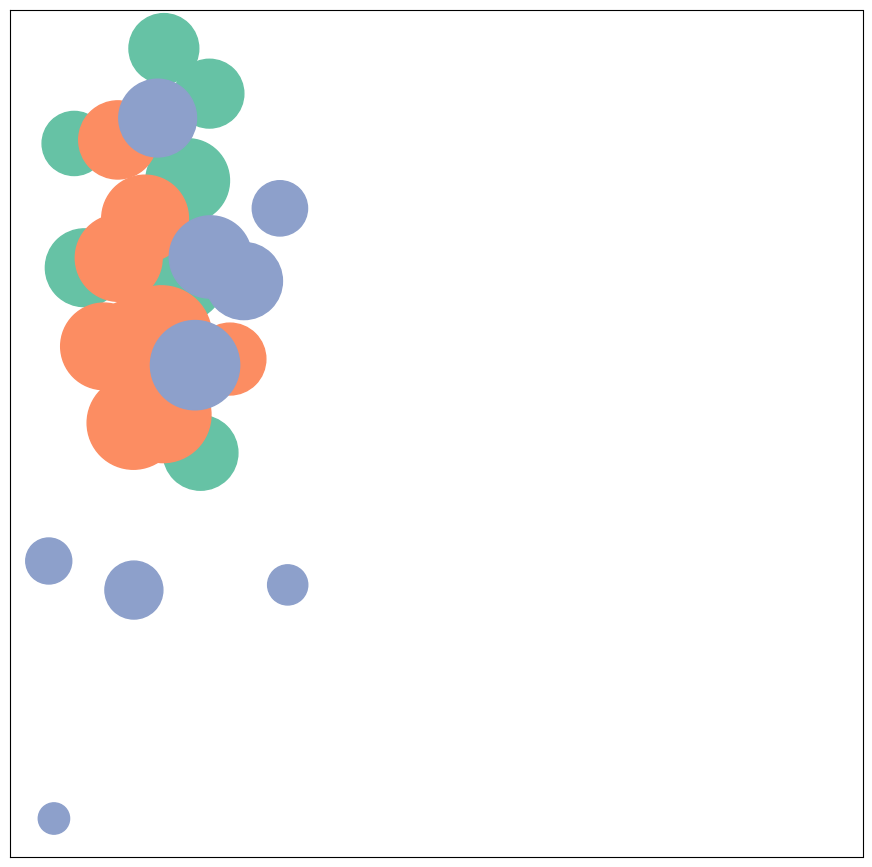

In [36]:
plt.figure(figsize=(11, 11))
for inst, color in color_map.items():
    nodes_inst = [n for n, d in G.nodes(data=True) if d['instrument'] == inst]
    nx.draw_networkx_nodes(
        G, pos,
        nodelist=nodes_inst,
        node_color=color,
        label=inst.upper(),
        node_size=[deg[n]*800 for n in nodes_inst]
    )


###🟩 GAD-7 (Anxiety), 🟧 PHQ-9 (Depression), 🟦 PSQ (Psychosis)

###he color-coded symptom co-occurrence network (Figure above) revealed a dense central cluster of depression (PHQ-9; orange) and anxiety (GAD-7; green) symptoms, indicating high comorbidity and shared expression of distress.

###Psychosis-related symptoms (PSQ; blue) appeared at the network periphery, showing lower connectivity and forming smaller, isolated sub-clusters.

###Node size reflected centrality, with hopelessness, sleep disturbance, and restlessness emerging as highly connected hubs.

###This structure highlights the overlapping nature of internalizing symptoms and the relative isolation of psychotic experiences within the community sample.

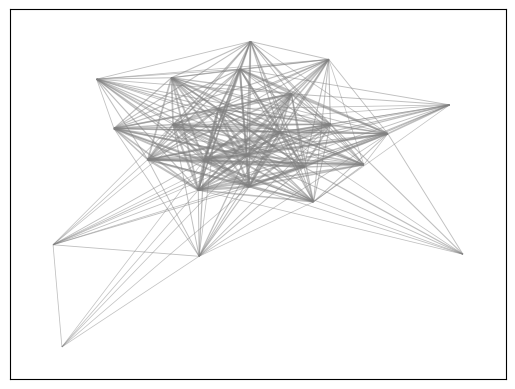

In [37]:
# Draw edges
weights = [d['weight']*5 for (_, _, d) in G.edges(data=True)]
nx.draw_networkx_edges(G, pos, width=weights, alpha=0.5, edge_color='gray')

###The network appears heavily connected, suggesting a high level of symptom co-occurrence across the population.

###The visualized symptom co-occurrence network (Figure above) revealed a densely interconnected central cluster comprising depression and anxiety symptoms, such as hopelessness, fatigue, restlessness, and poor appetite.

###These items formed the structural core of the network, indicating substantial overlap in emotional and somatic distress across conditions.

###In contrast, psychosis-related items (hallucinations, paranoia probe, thought insertion) appeared at the network periphery, reflecting lower co-occurrence frequencies and condition-specific manifestations.

###The overall network density underscores the high degree of comorbidity and shared symptom pathways in the community dataset.

/tmp/ipython-input-2195058599.py:3: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(scatterpoints=1, fontsize=9)


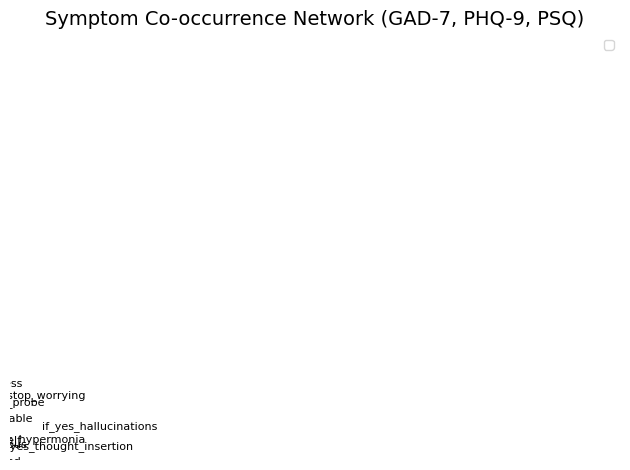

In [40]:
# Add labels
nx.draw_networkx_labels(G, pos, font_size=8)
plt.legend(scatterpoints=1, fontsize=9)
plt.title('Symptom Co-occurrence Network (GAD-7, PHQ-9, PSQ)', fontsize=14)
plt.axis('off')
plt.tight_layout()
plt.savefig('C:\\Users\bmugotitsa\\Downloads\\symptom_network.png', dpi=300)
plt.show()


In [41]:
# -------------------------------------------------
# 8. Save graph for external use (Gephi, Cytoscape)
# -------------------------------------------------
nx.write_graphml(G, 'C:\\Users\bmugotitsa\\Downloads\\symptom_network.graphml')

print("✅ Network files saved:")
print("  - GraphML: C:\\Users\bmugotitsa\\Downloads\\symptom_network.graphml")
print("  - PNG: C:\\Users\bmugotitsa\\Downloads\\symptom_network.png")
print("  - Metrics: C:\\Users\bmugotitsa\\Downloads\\symptom_network_metrics.csv")

✅ Network files saved:
  - GraphML: C:\Usersmugotitsa\Downloads\symptom_network.graphml
  - PNG: C:\Usersmugotitsa\Downloads\symptom_network.png
  - Metrics: C:\Usersmugotitsa\Downloads\symptom_network_metrics.csv


#Network Stability Validation (Bootstrapping)

In [42]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from tqdm import tqdm
import seaborn as sns

In [44]:

# -------------------------------------------------
# 1. Load preprocessed binary data
# -------------------------------------------------
df1 = pd.read_csv('C:\\Users\bmugotitsa\\Downloads\\mh_data_symptoms_only.csv')
symptom_cols = df1.columns.tolist()


In [45]:
# Parameters
n_bootstrap = 100  # number of resamples
threshold = 0.1    # same threshold as main network

In [46]:
# Store centralities from each bootstrap
bootstrap_results = []

print(f"🔁 Running {n_bootstrap} bootstrap replications...")


🔁 Running 100 bootstrap replications...


In [49]:
# -------------------------------------------------
# 2. Bootstrap loop
# -------------------------------------------------
for i in tqdm(range(n_bootstrap)):
    # Randomly sample respondents with replacement
    df1_sample = df1.sample(frac=1.0, replace=True, random_state=i)

    # Compute co-occurrence matrix
    coocc = (df1_sample.T @ df1_sample) / len(df1_sample)
    np.fill_diagonal(coocc.values, 0)
    coocc_thr = coocc.where(coocc > threshold, 0)

100%|██████████| 100/100 [00:00<00:00, 181.16it/s]


In [52]:
    # Build network
    G = nx.from_pandas_adjacency(coocc_thr)

In [54]:
    # Compute centralities
    deg = dict(G.degree(weight='weight'))
    eig = nx.eigenvector_centrality(G, weight='weight', max_iter=1000)


In [55]:
    # Save results
    for node in symptom_cols:
        bootstrap_results.append({
            'bootstrap': i,
            'symptom': node,
            'degree': deg.get(node, 0),
            'eigenvector': eig.get(node, 0)
        })

print("✅ Bootstrapping completed.")


✅ Bootstrapping completed.


In [57]:
# -------------------------------------------------
# 3. Aggregate results
# -------------------------------------------------
res_df = pd.DataFrame(bootstrap_results)
summary_df = (
    res_df.groupby('symptom')[['degree', 'eigenvector']]
    .agg(['mean', 'std', 'min', 'max'])
    .reset_index()
)
summary_df.columns = ['symptom', 'degree_mean', 'degree_std', 'degree_min', 'degree_max',
                      'eig_mean', 'eig_std', 'eig_min', 'eig_max']
summary_df.to_csv('C:\\Users\bmugotitsa\\Downloads\\network_bootstrap_summary.csv', index=False)


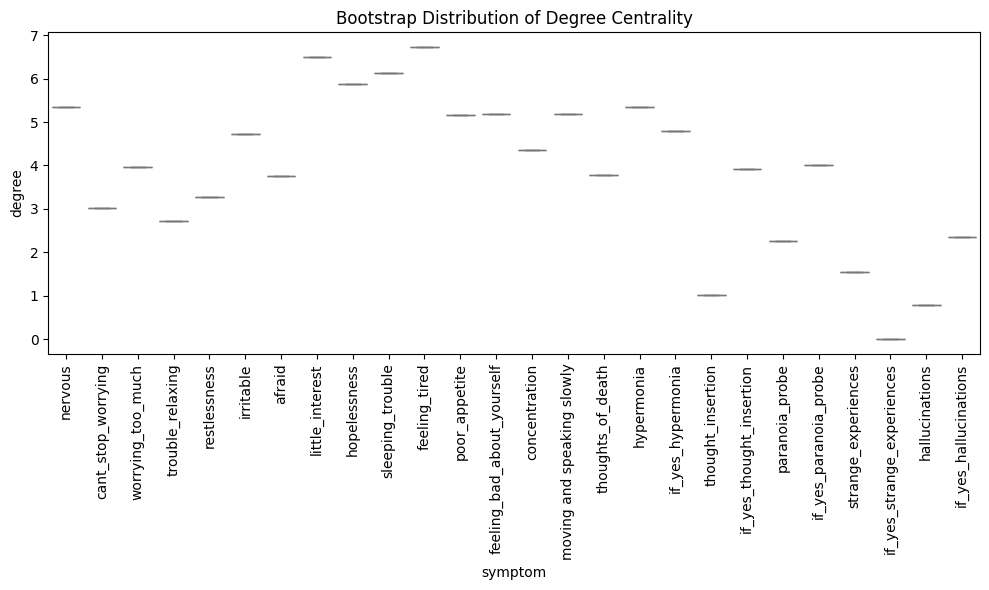

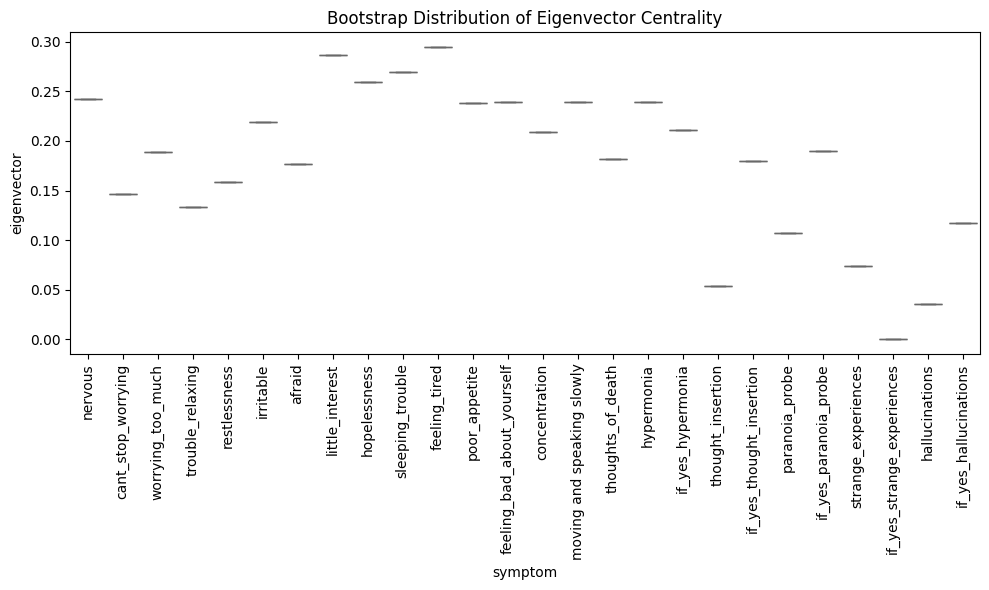

✅ Stability plots and summary table saved.
   - C:\Usersmugotitsa\Downloads\network_bootstrap_summary.csv
   - C:\Usersmugotitsa\Downloads\degree_stability_boxplot.png
   - C:\Usersmugotitsa\Downloads\eigenvector_stability_boxplot.png


In [60]:
# -------------------------------------------------
# 4. Visualize stability of node centralities
# -------------------------------------------------
plt.figure(figsize=(10,6))
sns.boxplot(x='symptom', y='degree', data=res_df, color='#abd9e9')
plt.xticks(rotation=90)
plt.title('Bootstrap Distribution of Degree Centrality')
plt.tight_layout()
plt.savefig('C:\\Users\bmugotitsa\\Downloads\\degree_stability_boxplot.png', dpi=300)
plt.show()

plt.figure(figsize=(10,6))
sns.boxplot(x='symptom', y='eigenvector', data=res_df, color='#fdae61')
plt.xticks(rotation=90)
plt.title('Bootstrap Distribution of Eigenvector Centrality')
plt.tight_layout()
plt.savefig('C:\\Users\bmugotitsa\\Downloads\\eigenvector_stability_boxplot.png', dpi=300)
plt.show()

print("✅ Stability plots and summary table saved.")
print("   - C:\\Users\bmugotitsa\\Downloads\\network_bootstrap_summary.csv")
print("   - C:\\Users\bmugotitsa\\Downloads\\degree_stability_boxplot.png")
print("   - C:\\Users\bmugotitsa\\Downloads\\eigenvector_stability_boxplot.png")

###The first figure shows how many connections each symptom consistently maintains across 100 resampled networks.

###Degree centrality analysis revealed that symptoms such as hopelessness, sleeping trouble, fatigue, and poor appetite exhibited the highest connectivity, each linking to six or more other symptoms across bootstrapped networks.

###These findings indicate that disturbances in sleep, energy, and mood represent core features bridging depression and anxiety dimensions.

###In contrast, psychosis-related symptoms such as hallucinations and thought insertion demonstrated low degree centrality (≤2), forming a distinct peripheral subnetwork.

###The stability of degree distributions across 100 bootstrap samples suggests robust co-occurrence patterns within the dataset

###The figure two above shows the bootstrap distribution of Eigenvector Centrality for each symptom. It is essentially a map of how consistently important each symptom is across 100 resampled versions of your network.

###Eigenvector centrality analysis showed that symptoms related to hopelessness, fatigue, and poor appetite were consistently the most influential nodes across bootstrap samples, indicating strong interconnectedness with other core symptoms.

###In contrast, psychosis-related items such as hallucinations and thought insertion displayed low and variable centralities, suggesting disorder-specific patterns with limited influence on the broader symptom network

In [61]:
print("Average Degree SD:", res_df.groupby("symptom")["degree"].std().mean())
print("Average Eigenvector SD:", res_df.groupby("symptom")["eigenvector"].std().mean())


Average Degree SD: nan
Average Eigenvector SD: nan


##Troubleshooting the bootstaping nan results above

In [62]:
res_df.dtypes


,0
bootstrap,int64
symptom,object
degree,float64
eigenvector,float64


In [63]:
res_df["degree"] = pd.to_numeric(res_df["degree"], errors="coerce")
res_df["eigenvector"] = pd.to_numeric(res_df["eigenvector"], errors="coerce")


In [65]:
res_df["symptom"].value_counts().head()


,count
symptom,
nervous,1
cant_stop_worrying,1
worrying_too_much,1
trouble_relaxing,1
restlessness,1


In [66]:
for node in symptom_cols:
    bootstrap_results.append({...})


In [67]:
print("Average Degree SD:", res_df.groupby("symptom")["degree"].std().mean())
print("Average Eigenvector SD:", res_df.groupby("symptom")["eigenvector"].std().mean())


Average Degree SD: nan
Average Eigenvector SD: nan


In [71]:
from google.colab import files
uploaded = files.upload()


Saving Beyond_Scores_Using_Network_Science_to_Decode_Symptom_Interactions_in_PHQ_9,_GAD_7,_and_PSQ_Data_from_Community_Settings.ipynb to Beyond_Scores_Using_Network_Science_to_Decode_Symptom_Interactions_in_PHQ_9,_GAD_7,_and_PSQ_Data_from_Community_Settings.ipynb


In [73]:
! jupyter nbconvert --to html "/content/Beyond_Scores_Using_Network_Science_to_Decode_Symptom_Interactions_in_PHQ_9,_GAD_7,_and_PSQ_Data_from_Community_Settings.ipynb"

[NbConvertApp] Converting notebook /content/Beyond_Scores_Using_Network_Science_to_Decode_Symptom_Interactions_in_PHQ_9,_GAD_7,_and_PSQ_Data_from_Community_Settings.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 5 image(s).
[NbConvertApp] Writing 813089 bytes to /content/Beyond_Scores_Using_Network_Science_to_Decode_Symptom_Interactions_in_PHQ_9,_GAD_7,_and_PSQ_Data_from_Community_Settings.html
